## Part 1 : Medical Appointment No-Shows: Exploratory Data Analysis (EDA)

### Introduction:

    This analysis explores the Brazilian Medical Appointment No-Shows dataset to understand its structure, identify patterns, and examine factors associated with missed appointments.

    The exploration focuses on patient demographics, medical conditions, socioeconomic factors, neighborhoods, scheduling intervals, and SMS reminders.

**Dataset:** Brazilian Medical Appointment No-Shows (Kaggle)

**Source:** `KaggleV2-May-2016.csv`

**Total Records:** 110,527

**Baseline No-show Rate:** Approximately 20%


#### Table of Contents

     1. Project Overview
     
     2. Environment Setup

     3. Data Preparation for Plotting

     4. Exploratory Data Analysis
     
     5. Statistical Methods
    
     6. Key Findings

     7. Visualizations

     8. Conclusions & Recommendations

     9. References

### **1. Project overview:**

#### Business problem: 
    The healthcare facility experiences missed appointments, reducing scheduling efficiency and limiting access to available appointments.

#### Business objective:
    Identify factors associated with patient no-shows and develop evidence-based recommendations to help reduce the no-show rate from 20%.

#### Primary KPI:
    No-show rate.

#### Secondary KPIs:
    Attendance rate and SMS reminder coverage.

#### Potential investigation areas:

    - Patient demographics
    - Appointment scheduling intervals
    - SMS reminders
    - Neighbourhoods
    - Medical conditions
    - Appointment dates

#### Key questions:
    1. What factors are most strongly associated with medical appointment no-shows?

    2. Which variables demonstrate statistically significant and practically meaningful relationships with attendance?

    3. How do scheduling intervals, patient characteristics, and SMS reminders relate to no-show behavior?

    4. Are there specific patient segments or appointment patterns associated with higher no-show rates?

    5. What insights can be translated into actionable recommendations to improve appointment attendance

### **2. Environment Setup**

In [1]:
# IMPORTING DEPENDENCIES

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Enabling inline plotting in the notebook 
%matplotlib inline

# Core libraries for data analysis
import numpy as np, pandas as pd, os

# Scipy library
from scipy.stats import pointbiserialr, spearmanr, ttest_ind, chi2_contingency, chi2

# Set up parameters in pandas
pd.set_option('display.notebook_repr_html', True, 'display.max_rows', 1000, 'display.max_columns', 100,
              'display.float_format', lambda x:"{:.2f}".format(x))

# Seaborn and Matplotlib for plotting
import matplotlib.pyplot as plt, seaborn as sns

from pathlib import Path

# Set up parameters in Matplotlib
params = {'axes.titlesize':10.2, 'axes.spines.top':False, 'axes.spines.right':False,
          'xtick.labelsize':8.2, 'ytick.labelsize':8.2, 'figure.figsize':[9.8, 8], 'font.size':8}


plt.rcParams.update(params)

### **3. Data Loading & Initial Inspection**
    Downloading dataset from kaggle website require API from personal account. There we have create an account if we don not have one!

In [2]:
# 3.1 Load dataset from path

DATA_PATH = Path('KaggleV2-May-2016.csv')

# Check csv file exeists
if not DATA_PATH.exists():
    raise FileNotFoundError(f'Dataset not found at {DATA_PATH},\
    please download dataset from kaggle and place it the same directory.')

# Load and display dataset
data = pd.read_csv(DATA_PATH, parse_dates=['ScheduledDay', 'AppointmentDay'])
data.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,29872499824296.00,5642903,F,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,558997776694438.00,5642503,M,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4262962299951.00,5642549,F,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,867951213174.00,5642828,F,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8841186448183.00,5642494,F,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,No


### **4. Descriptive Analysis:**

    Descriptive statistics provide insight into the dataset's structure, helping to identify missing values, unusual observations, and data types.




#### 4.1 Info:
    This returns a summary of the dataset's characteristics, including its shape, which consists of the number of rows and columns. Additionally, it provides information about the column names, their respective data types, and any missing values within the dataset

In [3]:
# 4.1.a Quick overview to detect nulls and check data types.
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype              
---  ------          --------------   -----              
 0   PatientId       110527 non-null  float64            
 1   AppointmentID   110527 non-null  int64              
 2   Gender          110527 non-null  object             
 3   ScheduledDay    110527 non-null  datetime64[ns, UTC]
 4   AppointmentDay  110527 non-null  datetime64[ns, UTC]
 5   Age             110527 non-null  int64              
 6   Neighbourhood   110527 non-null  object             
 7   Scholarship     110527 non-null  int64              
 8   Hipertension    110527 non-null  int64              
 9   Diabetes        110527 non-null  int64              
 10  Alcoholism      110527 non-null  int64              
 11  Handcap         110527 non-null  int64              
 12  SMS_received    110527 non-null  int64              
 13  No-show       

    Summary: 110,527 rows × 14 columns. All features have non-null values. ScheduledDay and AppointmentDay were string object but were processed as datetime objects on data loading.

#### 4.2 Satistical summary:

    The "describe()" is a useful function for generating descriptive statistics of a DataFrame or Series to helping us quickly understand its distribution and key properties.

In [4]:
# 4.2.a Summary statistics to find outliers and frequency counts
data.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
PatientId,110527.00,NaN,NaN,NaN,147496265710394.06,39217.84,4172614444192.00,31731838713978.00,94391720898175.00,999981631772427.00,256094920291739.09
AppointmentID,110527.00,NaN,NaN,NaN,5675305.12,5030230.00,5640285.50,5680573.00,5725523.50,5790484.00,71295.75
Gender,110527,2,F,71840,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ScheduledDay,110527,NaN,NaN,NaN,2016-05-09 07:49:15.846273024+00:00,2015-11-10 07:13:56+00:00,2016-04-29 10:27:01+00:00,2016-05-10 12:13:17+00:00,2016-05-20 11:18:37+00:00,2016-06-08 20:07:23+00:00,NaN
AppointmentDay,110527,NaN,NaN,NaN,2016-05-19 00:57:50.008233472+00:00,2016-04-29 00:00:00+00:00,2016-05-09 00:00:00+00:00,2016-05-18 00:00:00+00:00,2016-05-31 00:00:00+00:00,2016-06-08 00:00:00+00:00,NaN
Age,110527.00,NaN,NaN,NaN,37.09,-1.00,18.00,37.00,55.00,115.00,23.11
Neighbourhood,110527,81,JARDIM CAMBURI,7717,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Scholarship,110527.00,NaN,NaN,NaN,0.10,0.00,0.00,0.00,0.00,1.00,0.30
Hipertension,110527.00,NaN,NaN,NaN,0.20,0.00,0.00,0.00,0.00,1.00,0.40
Diabetes,110527.00,NaN,NaN,NaN,0.07,0.00,0.00,0.00,0.00,1.00,0.26


#### 4.2.b  Observations:

        . PatientId and AppointmentID do not appear to be useful for prediction. However, we can perform feature engineering on these variables before deciding whether to remove them.

        . Negative ages indicate data entry errors. We'll handle these negative values for the sake of our analysis, but it's important to let the healthcare management know about those entry errors to make sure what they might indicate.

        . Rare Age=115 is plausible but uncommon.

        . Handcap has unusual values; needs binary encoding. Just like for age column, it's also important to investigate about handicap feature the distributions (having 0 to 4 categories) before deciding how to process them.

        . No-show is imbalanced (~20% no-shows).

### **5. Data Cleaning:**
    Data cleaning includes preprocessing our dataset suitable for plotting the features for further exploration.
    

In [5]:
# 5.1 Create a data cleaning function for exploratory analysis
def data_cleaning(data):
    '''Returns features of the dataset suitable for
    exploratory analysis. '''
    
    # Make a copy of data to preserve the original
    df = data.copy()
    
    # Convert features' name into lower cases
    df.columns = df.columns.str.lower()
    
    # Convert Age into positive values
    if 'age' in df.columns:
        nu_neg = df[df['age'] < 0]['age'].count()
        if (nu_neg / df.shape[0])*100 < .05 :
            # Remove negative values
            df = df.loc[~(df.age < 0)]

    
    # Encode handcap
    if 'handcap' in df.columns:   # If condition used to present error
        df.rename(columns={'handcap':'handicap'}, inplace=True)
        # Convert 'handicap' feature into a binary
        df['handicap'] = np.where(df['handicap'] == 0, 0, 1)
    
    
    # Create Datetime Components
    # Remove rows where appointmentday are inferior than scheduledday
    df = df.loc[~(df['appointmentday'].dt.date < df['scheduledday'].dt.date)]

    df['no-show'] = np.where(df['no-show'] == 'Yes', 1, 0)
        
    # Remove hours components and compute the difference between appointment and schedledday
    df['waitingdays'] = (df['appointmentday'].dt.normalize() - df['scheduledday'].dt.normalize()).dt.days

    df = df.sort_values(['patientid', 'scheduledday', 'appointmentid']).reset_index(drop=True)
    
    # Create appointmentday_weekday and appointmentday_hours components
    for column in ['scheduledday', 'appointmentday']:
         df[f"{column}_weekday"] = df[column].dt.weekday

    # Define first-appointment indicator
    base = df[['patientid', 'scheduledday']].copy()
    base['sched_date'] = base['scheduledday'].dt.normalize()
    base = base.rename_axis('rid').reset_index()

    past = df[['patientid', 'appointmentday', 'no-show']]
    m = base.merge(past, on='patientid')
    
    # Keep only appointments that were already over when this one was booked
    m = m.loc[m['appointmentday'] < m['sched_date']]

    hist = m.groupby('rid').agg(prev_appt=('no-show', 'size'),
                        prev_noshow=('no-show', 'sum'),
                        last_appt_day=('appointmentday', 'max'))
    df = df.join(hist)

    df[['prev_appt', 'prev_noshow']] = df[['prev_appt', 'prev_noshow']].fillna(0)

    df['noshow_rate'] = (df['prev_noshow'] / df['prev_appt']).where(df['prev_appt'] > 0, 0)

    df['days_since_last_appt'] = (df['scheduledday'].dt.normalize() - df['last_appt_day']).dt.days.fillna(0)
    
    # Define first appointment indicator
    df['is_first_appnt'] = (df['prev_appt'] == 0).astype(int)

    # Define feature where patient return back at their appointments
    df['is_returning'] = (df['prev_appt'] > 0).astype(int)
    
    
    # Drop Unnecessary Columns including scheduledday and appointmentday
    df.drop(['patientid', 'appointmentid', 'scheduledday', 'appointmentday', 'last_appt_day'], axis=1, inplace=True)

    # Return data frame
    return df
    
# Store cleaned dataset in a variable and display first 5 rows
df = data_cleaning(data)

df.head()

,gender,age,neighbourhood,scholarship,hipertension,diabetes,alcoholism,handicap,sms_received,no-show,waitingdays,scheduledday_weekday,appointmentday_weekday,prev_appt,prev_noshow,noshow_rate,days_since_last_appt,is_first_appnt,is_returning
0,F,44,PRAIA DO SUÁ,0,0,0,0,0,0,0,3,1,4,0.00,0.00,0.00,0.00,1,0
1,M,39,MARIA ORTIZ,0,0,1,0,0,0,0,0,2,2,0.00,0.00,0.00,0.00,1,0
2,F,33,CENTRO,0,0,0,0,0,0,0,0,2,2,0.00,0.00,0.00,0.00,1,0
3,M,12,FORTE SÃO JOÃO,0,0,0,0,0,0,0,3,4,0,0.00,0.00,0.00,0.00,1,0
4,F,14,FORTE SÃO JOÃO,0,0,0,0,0,1,0,7,4,4,0.00,0.00,0.00,0.00,1,0


### **6. Exploratory Data Analysis (EDA):**

    EDA is the process of visually and statistically exploring data to uncover patterns, trends, and relationships between variables. It involves creating various plots and charts to gain insights into the data and identify potential areas for further investigation.

    We can divide the exploratory data analysis into two parts: Univariate and Bivariate Plots.

#### 6.1 Univariate Analysis:

    This section examines each feature individually to understand data quality, detect anomalies, and identify potential predictors of appointment attendance.

#### 6.1.a Column Partioning for Plots:
    Column partioning involve separating columns into lists of continuous and categorical just for plotting purpose.

In [6]:
# 6.1.b Define list of continuous and categories features

cont_cols = ['age', 'waitingdays', 'days_since_last_appt', 'noshow_rate', 'prev_noshow']


cat_cols = ['gender', 'neighbourhood', 'scholarship', 'hipertension',
            'diabetes', 'alcoholism', 'handicap', 'sms_received', 'no-show', 
            'scheduledday_weekday', 'appointmentday_weekday', 'is_first_appnt', 'is_returning']

#### 6.2 Function for plotting feature distributions

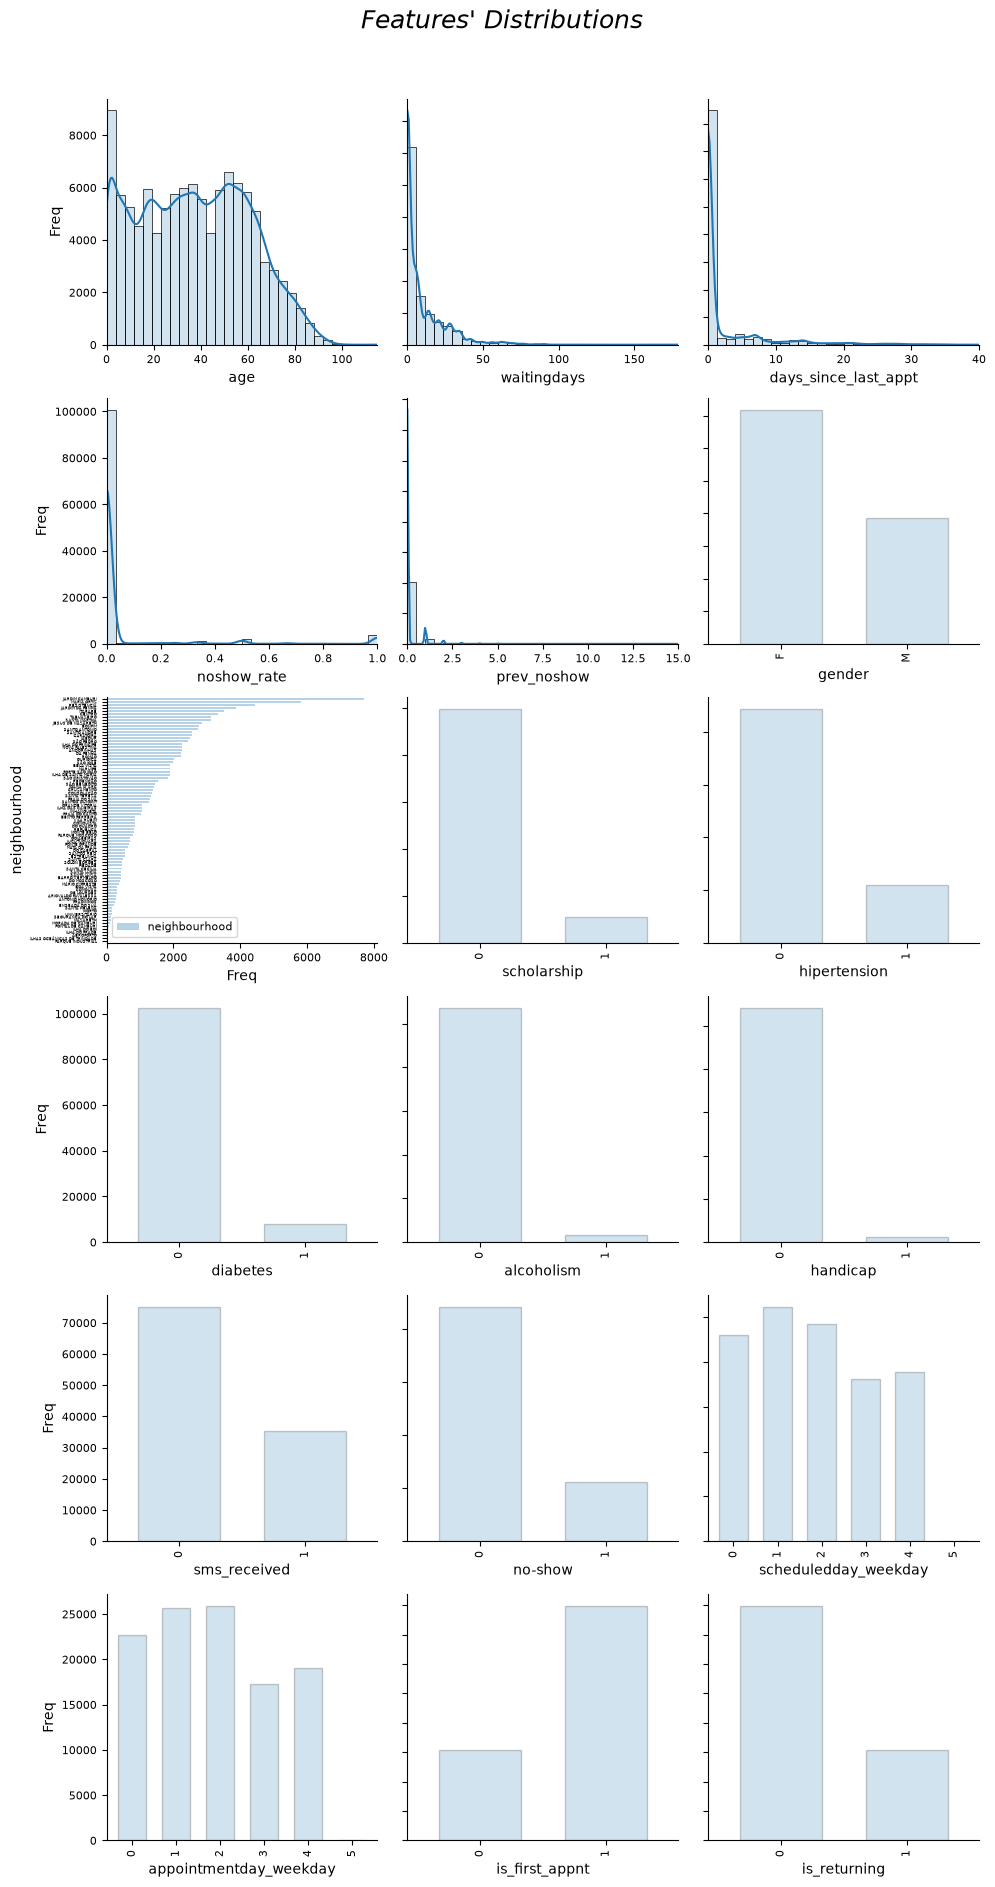

In [7]:
# 6.2.a Define a Univariate Plot
def univariate_plots(df, cont_cols, cat_cols):
    '''Returns a grid of continuous and categirical plots'''
    # Total of giving features
    total_cols = len(cont_cols) + len(cat_cols)
    
    # Number of rows to use in grid plot
    num_rows = int(np.ceil(total_cols / 2))

    # Number of columns to use in grid plot
    num_cols = min(total_cols, 3)
    
    # Initiate coun plot
    countplot = 1
    # Define figure for plot
    plt.figure(figsize=[10, 3 * num_rows])

    # Loop through continuous columns
    for column in cont_cols:
        # Set up grid plot
        plt.subplot(num_rows, num_cols, countplot)

        # Create a histogram plot for every continuous feature
        sns.histplot(x=df[column], bins=30, kde=True, alpha=.2)

        # Adjust x, and y axis
        plt.xlim([0, df[column].max()])
        plt.xlabel(column, fontsize=10)
        plt.ylabel('Freq', fontsize=10)

        # Increment the plot
        countplot+=1

    # Loop through categorical columns
    for column in cat_cols:
        # Set up grid plot
        plt.subplot(num_rows, num_cols, countplot)
        
        if column == 'neighbourhood':  # We selcted bc it's a nominal category
            # Display bars by values' order
            df[column].value_counts().sort_values().plot(kind='barh', width=.65, alpha=.33, label=column)
            plt.legend()
            plt.xlabel('Freq', fontsize=10)
            plt.ylabel(column, fontsize=10)
            plt.yticks(fontsize=3)

        else:
            df[column].value_counts().sort_index().plot(kind='bar', width=.65, #color='lightslategray',
                                                        alpha=.2, edgecolor='k', sharey=True)
            # Adjust x, and y axis label size
            plt.xlabel(column, fontsize=10)
            plt.ylabel('Freq', fontsize=10)

        # Increment plot
        countplot+=1
        
    plt.suptitle(" Features' Distributions", fontsize=18, y=1.015, style='italic')

    # Ajust padding between plots
    plt.tight_layout()

    # Show plot
    plt.show()

# Plot the features
univariate_plots(df, cont_cols, cat_cols)

#### 6.2.b Key Insights

**Age Distribution:**

- Most patients are adults and seniors, with relatively few children and very elderly patients. This suggests that age-related factors—such as chronic conditions or work constraints—may play a role in appointment adherence
- A small number of unrealistic ages and outliers appear, justifying cleaning and binning.

**Appointment Timing:**
- A large proportion of appointments are scheduled for the same day, producing a highly skewed waiting-time distribution.
- The clinic does not operate on Sundays, and appointments cluster heavily during weekdays and working hours.

**Chronic Conditions:**
- The prevalence of chronic diseases is low:
  - Hypertension and diabetes appear in a minority of patients.
  - Alcoholism and handicap occur in very small proportions.
- These features are **highly imbalanced**, suggesting limited standalone predictive power but potential value in interaction with age and appointment timing.

**Socioeconomic Indicator:**
- Only a small fraction of patients received scholarships, indicating socioeconomic imbalance that may influence attendance behavior.

**Communication:**
- Roughly half of the patients received SMS reminders, making this a potentially meaningful behavioral variable.

Overall, most medical and social features are heavily skewed, reinforcing the need for careful modeling and possibly resampling techniques.

**Target:**

    The dataset is heavily imbalanced, with roughly four times as many show-ups as no-shows. This imbalance explains why naïve models achieve high accuracy and motivates the use of resampling techniques later in the analysis.

#### 6.3 Bivariate Analysis:
    
    This section explores how individual features relate to the target variable (No-show), allowing us to identify behavioral and demographic factors associated with missed appointments.

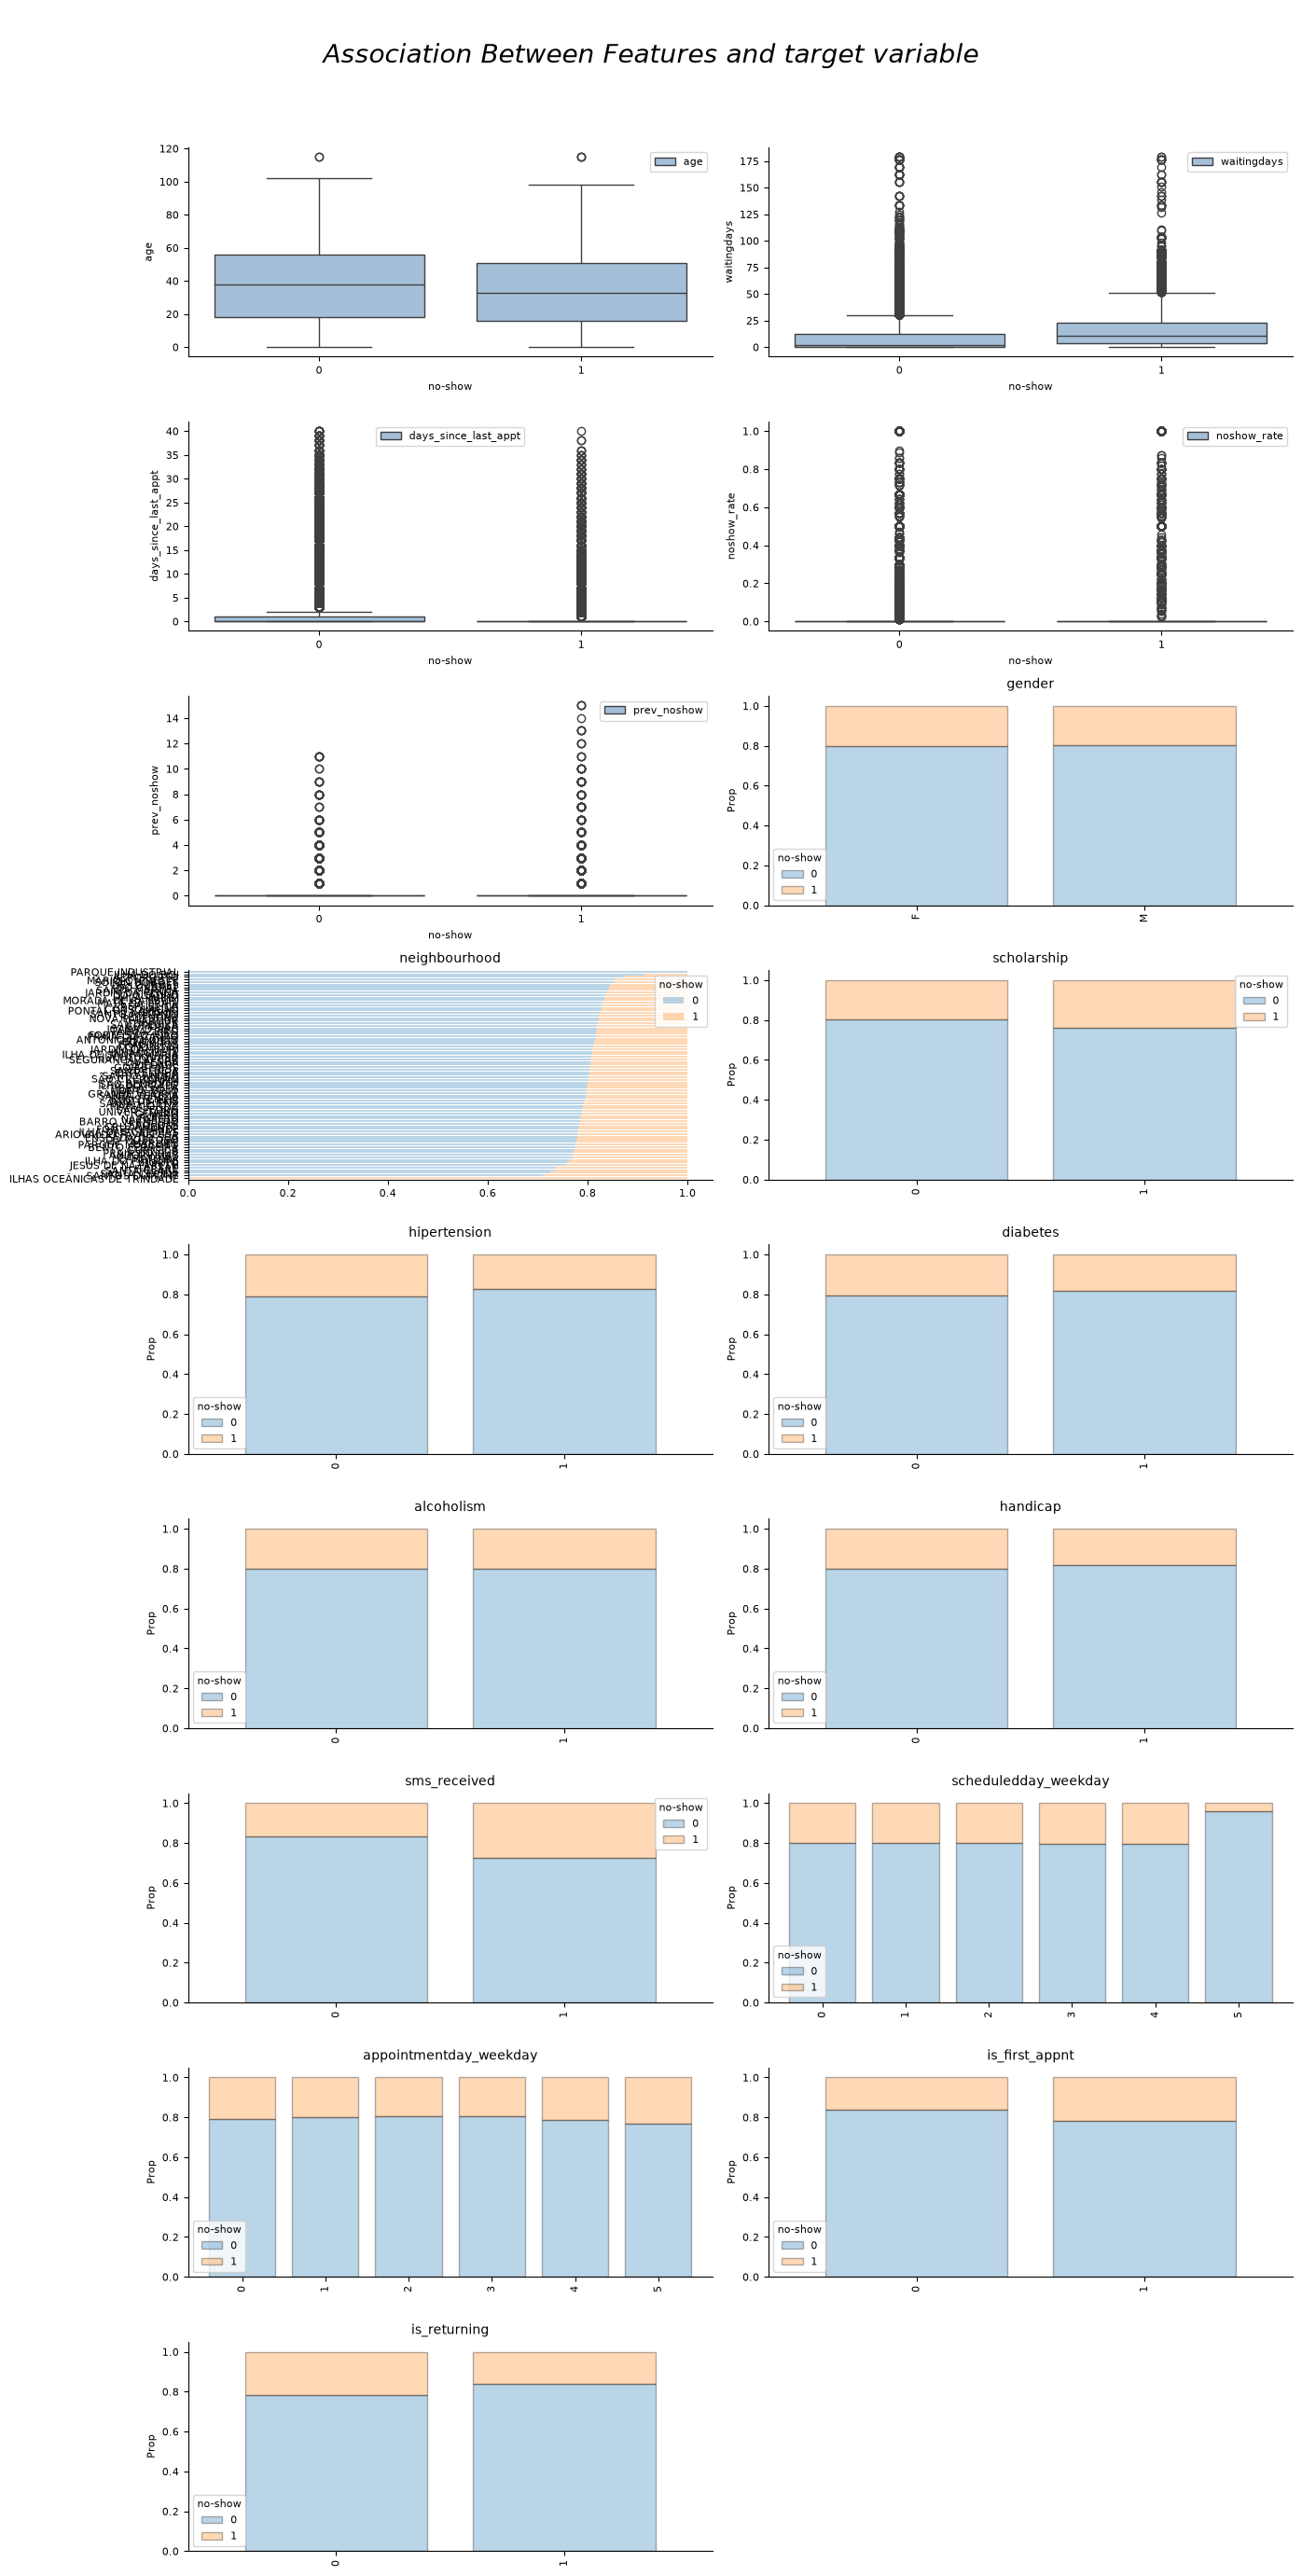

In [8]:
# 6.3.a Bivariate Function
def bivariate(df, cont_cols, cat_cols, target='no-show'):
    """Returns a grid of bivariate plot between features and target variable"""
    print('\n')
    countplot=1
    # Define a feature list
    cat_cols = [col for col in cat_cols if col != target]
    
    # Define number on rows columns for grid plot
    total_cols = len(cont_cols+cat_cols)

    # Number of rows and columns for the grid
    nrows = int(np.ceil(total_cols / 2))
    ncols = min(total_cols, 2)

    # Figure for the grid plot
    plt.figure(figsize=[14, 3*nrows])

    # Loop through columns
    for column in cont_cols:
        # Define axes for grid plots
        ax = plt.subplot(nrows, ncols, countplot)

        # Use seaborn for boxplot
        sns.boxplot(x=df[target], y=df[column], boxprops={'facecolor': (0.3, 0.5, 0.7, 0.5)},
                    label=column, ax=ax)
        ax.legend()

        # Increment the plot
        countplot+=1

    # Loop through catgorical columns and repeat the same thing
    for column in cat_cols:
        ax = plt.subplot(nrows, ncols, countplot)
        
        cros_prob = pd.crosstab(df[column], df[target], normalize='index')
        
        if column == 'neighbourhood':
            order = cros_prob[1].sort_values(ascending=False).index
            cros_prob.loc[order].plot(kind='barh', stacked=True, 
                            ax=ax, alpha=.3, width=.75)
            ax.set_ylabel(None)
            ax.set_title(column)
            
        else:
            # Create a plot for the rest of features
            cros_prob.plot(kind='bar', stacked=True, width=.8,
                           ax=ax, alpha=.3, edgecolor='k')

            ax.set_title(column)
            ax.set_xlabel('')
            plt.ylabel('Prop')

        # Increment the plot
        countplot+=1

    # Add a title for the figure
    plt.suptitle('\nAssociation Between Features and target variable', style='italic', fontsize=20, y=1.02)
    plt.tight_layout()

    # Show the plots
    plt.show()

# Generate the grid plot
bivariate(df, cont_cols, cat_cols)

#### 6.4 Statistical Tests:
    While bivariate plots are essential for building intuition, statistical tests are the "proof" that ensures our eyes aren't playing tricks on us.

#### 6.4.a Method 1: Two-sample t-test:
    This involves determining if the mean of a continuous variable (output var) across the categories (independent var) are different. For each feature, we test:

*   $H\_0: µ\_1 = µ\_2$ ("Assumes there is no significant difference between the means.")
*   $H\_1: µ\_1 ≠ µ\_2$ ("Assumes there is significant difference between the means.")

In [9]:
# 6.4.b Define a function that computes statistical tests
def ttest_score(df, column, target="no-show"):
    """Returns statistical test results between a continuous column and a binary

    target.
    """
    # Preserve the original dataset
    df = df.copy()

    # 1. Two-sample Independent T-test
    # Group the continuous feature based on the binary target categories
    groups = [df.loc[df[target] == i, column] for i in df[target].unique()]
    statistic, p_val = ttest_ind(*groups, equal_var=False)

    # 2. Point-Biserial Correlation
    # target (no-show) as input x, column (age/waitingdays) as input y
    r, p = pointbiserialr(df[target], df[column])

    # 3. Spearman Rank Correlation
    rho_a, p_a = spearmanr(df[column], df[target])

    # Return statistical values
    return {
        "Features": column,
        "T-Statistic": statistic,
        "T-P-value": p_val,
        "Significant": "Yes" if p_val < 0.05 else "No",
        "PointBiserial_r": r,
        "Spearman_rho": rho_a,
    }


# Define your continuous columns list (example mapping)
#cont_cols = ["age", "waitingdays"]

# Compute statistical test for all continuous columns and append to the list
ttest_score_features = []
for column in cont_cols:
    ttest_score_features.append(ttest_score(df, column, target="no-show"))

# Convert results into a dataframe and print
df_ttest = pd.DataFrame(ttest_score_features)
print("Two-sample Test Scores\n")
print(df_ttest.to_string(index=False) + "\n")


Two-sample Test Scores

            Features  T-Statistic  T-P-value Significant  PointBiserial_r  Spearman_rho
                 age        20.83       0.00         Yes            -0.06         -0.06
         waitingdays       -58.29       0.00         Yes             0.19          0.28
days_since_last_appt        20.90       0.00         Yes            -0.05         -0.06
         noshow_rate        -7.35       0.00         Yes             0.02          0.01
         prev_noshow        -9.08       0.00         Yes             0.04          0.01



#### 6.4.c Key Insights:
**Continuous features VS no-show:** 

    With p-values less than 0.05, we reject the null hypothesis, indicating a significant mean difference between the groups across all the continuous variables. While waitingdays shows a moderate effect size, the remaining features, on the other hand, depict negligible effect.

#### 6.4.d Method 2: Chi-Square and Cramer's V for Categorical Variables

    The Cramer's V test measures the association strength between two categorical variables.

- **Range:** 0 (no association) to 1 (strong association)
- **Interpretation:**
     
     - **p greater than 0.05: 'Not statistical significant**
     
     - **p less than 0.05 & V greater than 0.25:** Strong Association
  
     - **p less than .05 & 0.10 greater than V less or equal than 0.25:** Moderate Association
  
     - **p less than .05 & V less than 0.10:** Weak Association
  
Next we'll create a function to compute these tests.

In [10]:
# 6.4.e Create a function that computes statistical tests for two categorical features

# Define a bin list and corresponding label
bins = [-np.inf, 12, 18, 44, 64, np.inf]

labels = ['Children', 'Adolescents', 'Young Adult', 'Middle-Aged', 'Senior']

# Create agegroup column
df['agegrp'] = pd.cut(df.age, bins=bins, labels=labels)

if not 'agegrp' in cat_cols:
    cat_cols.append('agegrp')

# Define the function to compute statistical test
def chi2_and_cramers_test(df, column, target='no-show'):
        """Retuns p and cramer's V values of a given column"""
        contingency = pd.crosstab(df[column], df[target])

        # Compute statistical test of contingency table
        chi2, p_val, dof, _ = chi2_contingency(contingency)

        r, k = contingency.shape

        n = df.shape[0]

        pchi2 = chi2 / n

        pchi2corr = max(0, pchi2 - ((r-1)*(k-1)) / (n-1))
        rcorr = r - (r - 1)**2 / (n-1)
        kcorr = k - (k - 1)**2 / (n-1)
        v = np.sqrt(pchi2corr / min((kcorr-1), (rcorr-1)))

        # Return v and p values
        return v, p_val

# Exlude target from categorical list
cat_cols = [x for x in cat_cols if x != 'no-show']

# Define an empty list for cramers and p values
cramers_v_test_score = []

# Compute p and cramers' value for all variables
for column in cat_cols:
    v, p = chi2_and_cramers_test(df, column, target='no-show')

    if p < .05 and v > .25:
        strenght = 'Strong'
    elif p < .05 and v > .10:
        strenght = 'Moderate'
    elif p> .05 and v < 0.02:
        strenght = 'Negligible'
    else:
        strenght = 'Weak'

    cramers_v_test_score.append({'features': column,
                                 'p-value': p,
                                 'cramer v': v,
                                 'Strength': strenght})

df_cramers = pd.DataFrame(cramers_v_test_score).sort_values('cramer v', ascending=False)

# Display p-value and cramer results
print('\nCramers V test Scores:\n')
print(df_cramers.to_string(index=False))


Cramers V test Scores:

              features  p-value  cramer v   Strength
          sms_received     0.00      0.13   Moderate
                agegrp     0.00      0.08       Weak
        is_first_appnt     0.00      0.06       Weak
          is_returning     0.00      0.06       Weak
         neighbourhood     0.00      0.06       Weak
          hipertension     0.00      0.04       Weak
           scholarship     0.00      0.03       Weak
              diabetes     0.00      0.01       Weak
appointmentday_weekday     0.00      0.01       Weak
              handicap     0.01      0.01       Weak
  scheduledday_weekday     0.11      0.01 Negligible
                gender     0.17      0.00 Negligible
            alcoholism     0.97      0.00 Negligible


#### 6.4.f Key Insights:

    While a few features including Scheduledday_weekday, gender, and alcoholism show no statistical significance, sms_received indicates moderate, significant association with no-show, and the remaining features show very weak associations.
    
    Neighbourhood no-show rates mostly fall between about 15% and 23%, close to the overall rate of about 20%. The most extreme rates come from neighbourhoods with very few appointments (e.g., Ilhas Oceânicas de Trindade, n = 2, at nearly 100%; Parque Industrial, n = 1), so they shouldn’t be interpreted. Only a few well-populated neighbourhoods sit noticeably above the overall rate, consistent with the weak association found (Cramér’s V = 0.06).

### **7. Feature Interactions**
Feature interaction analysis helps visualize how the effect of one feature on the target variable depends on another feature. By combining at least two predictors along with the target variable, we can identify whether the relationship between a feature and the outcome changes across different levels of a second feature.

Let's examine the interactions between **waitingdays vs sms received** in relation to appointment no-shows.

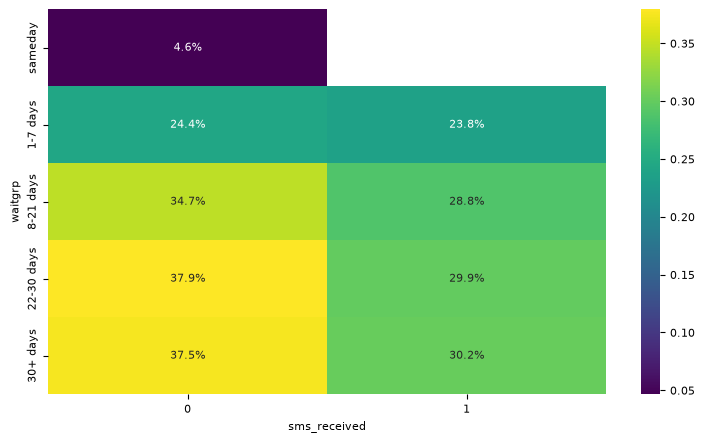

In [11]:
# 7.1.a Convert waitingdays into categorical feature
bins=[-np.inf, 0, 7, 21, 30, np.inf]
labels = ['sameday', '1-7 days', '8-21 days', '22-30 days', '30+ days']
df['waitgrp'] = pd.cut(df['waitingdays'], bins=bins, labels=labels)


# 7.1.b Create a heatmap Visualization between waitgrp and sms on no-show
# Define figure for plot
plt.figure(figsize=[9, 5])
# Plot the pivot table
sns.heatmap(df.pivot_table(index='waitgrp', columns='sms_received',
            values='no-show'), fmt='.1%', cmap='viridis', annot=True);

#### 7.1.c Key insights

    The heatmap shows no-show rates by waiting time, split by SMS receipt. Without an SMS, the no-show rate rises from about 5% for same-day appointments to about 38% for waits of three weeks or more. Within each group waiting longer than a week, patients who received an SMS missed fewer appointments than those who did not (e.g., 28.8% vs 34.7% for 8-21 days). Overall, SMS recipients can look worse because SMS is mostly sent for appointments booked further ahead, which are riskier to begin with (the SMS paradox). This is an association, not proof that SMS reduces no-shows.

### **8. Conclusions & Recommendations**

#### **Summary of Findings:**

This analysis identified three tiers of features based on practical relevance:

**Tier 1: Key Drivers (Focus Here)**

        • SMS Reminders (Cramer's V = 0.1264): moderate predictor, but confounded by lead time. Not ineffective; rather, sent to high-risk patients.

        • Waitingdays (Point Biserial ~ .19 & Spearmanr ~ .28): moderate direct predictor and practical impact. The longer patients wait the chance they miss their appointments due changed circumstances...
        
**Tier 2: Weak but Significant Factors**
        
        • Neighbourhood, appointmentday_weekday, is_first_appnt, is_returning, agegrp, scholarship and certain health conditions (Cramer's V < 0.08) depict minimal practical impact.
        
        • Days_since_last_appt, noshow_rate, and prev_noshow (with Spearmanr < .10) seem to have pratical minimal impact exhibiting patients' past behaviors.


**Tier 3: Negligible Factors**

            • Gender, scheduledday_weekday, and alcoholism have no statistically significant association with no-shows which we will deprioritize as inputs for the predictive modeling.

#### Note:
    history features overlap with each other, so check multicollinearity before fitting linear models and keep only one of is_first_appnt / is_returning.
    

#### **Actionable Recommendations**


**Scheduling & SMS Optimization:**

            • Reduce appointments waiting time as much as possible and place overflow patients on a dynamic waiting list.

            • Test whether sending SMS to more patients lowers no-shows, for example with a pilot or A/B test
            
            • Let patients confirm or cancel by reply.
            
            • Based on their responses, healthcare management can proactively backfill canceled slots.


**Next I will perform a predictive modeling for Brazilian no-show apointment medical dataset**

### **9. References**

**Dataset**
- Hoppen, J. *Medical Appointment No Shows* (KaggleV2-May-2016). Kaggle.
  https://www.kaggle.com/datasets/joniarroba/noshowappointments

**Methods**
- Bergsma, W. (2013). A bias-correction for Cramér's V and Tschuprow's T.
  *Journal of the Korean Statistical Society*, 42(3), 323-328.
- Welch, B. L. (1947). The generalization of "Student's" problem when several
  different population variances are involved. *Biometrika*, 34(1-2), 28-35.

**Software**
- pandas, NumPy, SciPy (`scipy.stats`: `ttest_ind`, `pointbiserialr`, `spearmanr`,
  `chi2_contingency`), Matplotlib, seaborn.